In [20]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import pandas as pd
from astropy.io import fits

## PART 1

In [5]:
stars = ["O5V", "O8V", "B1p5V", "B6V", "A6V", "F0V", "G6V", "K4V", "M0V", "M5V"]

spectra = {
    star: pd.read_csv(f"{star}.asc", sep=r"\s+", header=None, names=["wavelength", "flux"])
    for star in stars}

print(spectra["O5V"].columns.tolist())

['wavelength', 'flux']


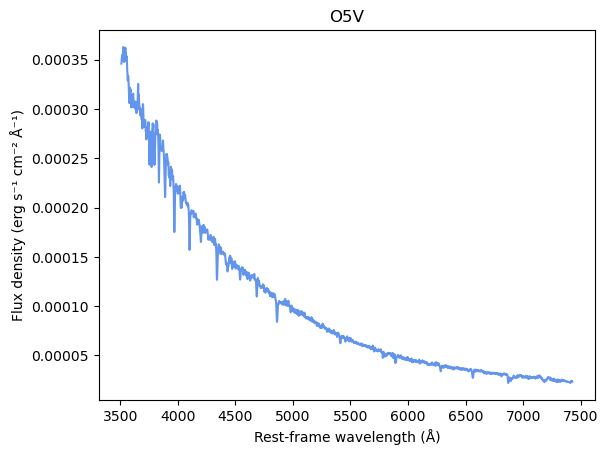

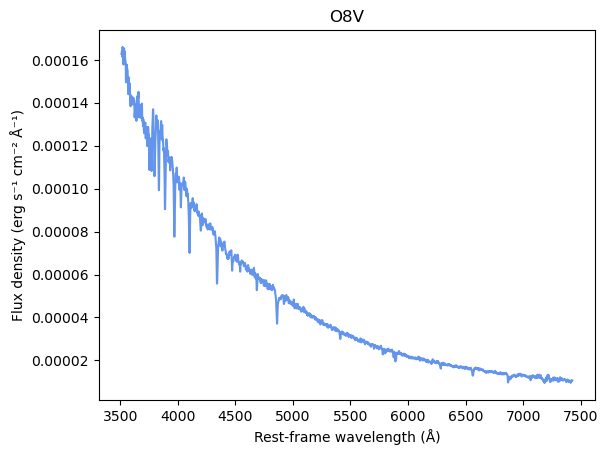

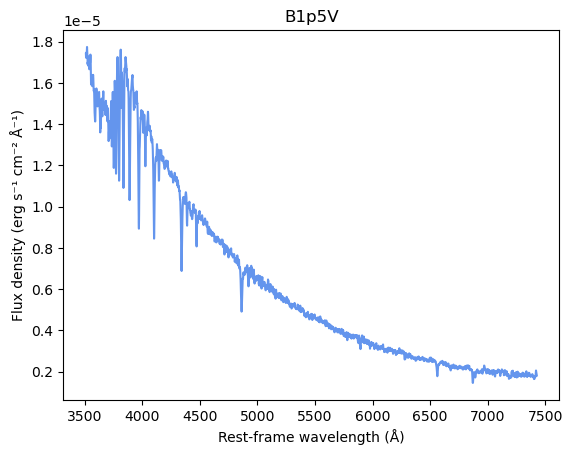

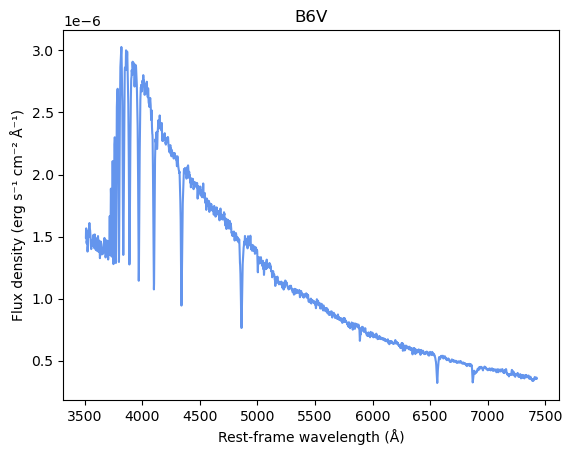

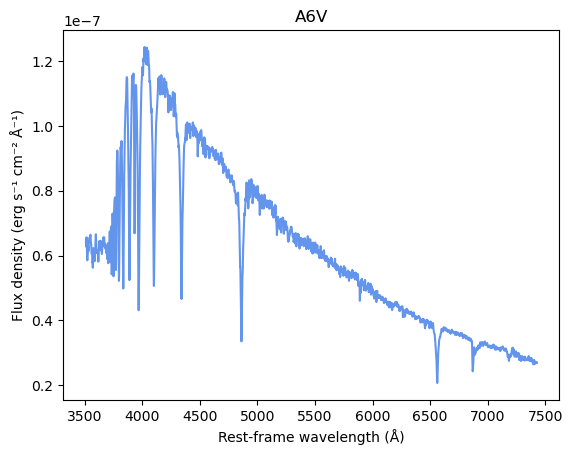

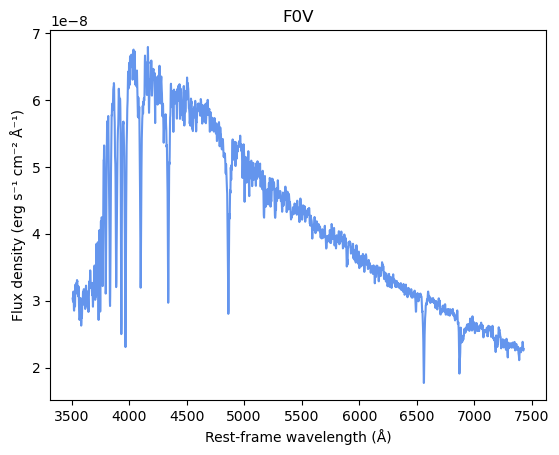

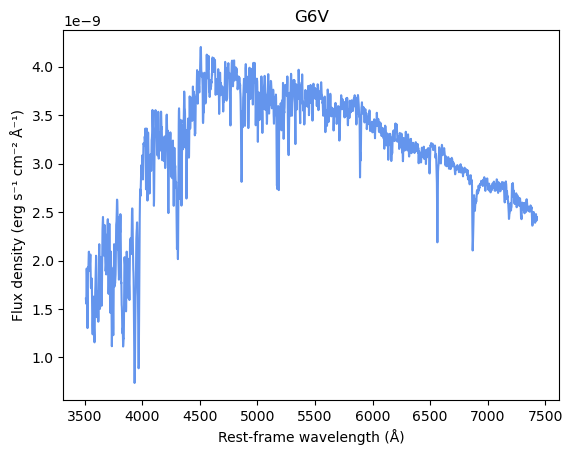

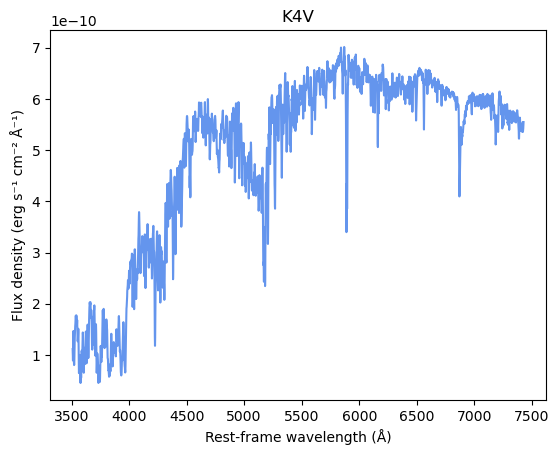

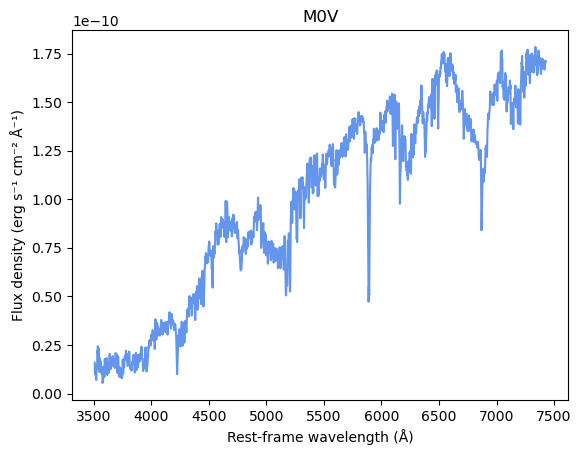

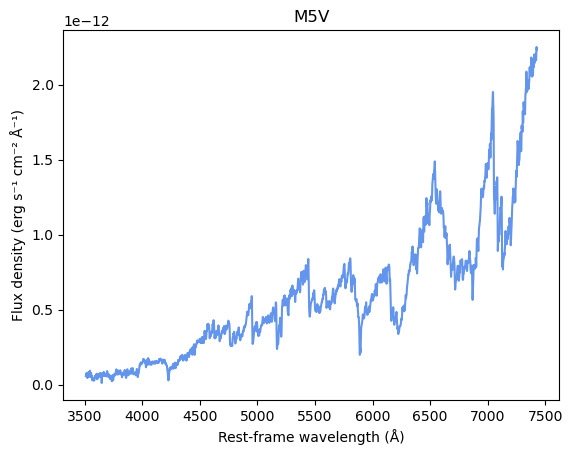

In [6]:
for star, spectrum in spectra.items():
    spectrum.plot(x="wavelength", y="flux", color="cornflowerblue", title=star, xlabel="Rest-frame wavelength (Å)",
        ylabel="Flux density (erg s⁻¹ cm⁻² Å⁻¹)",
        legend=False)

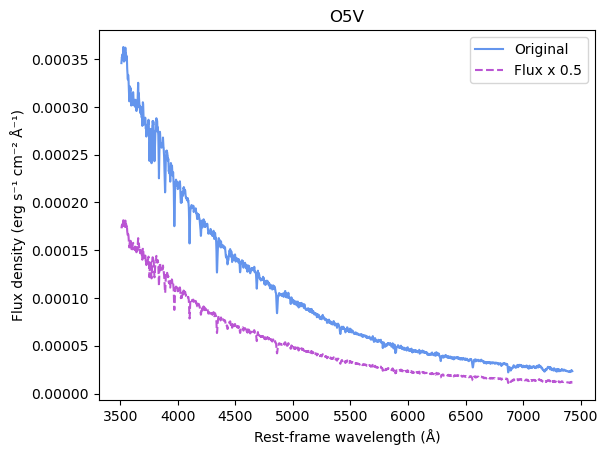

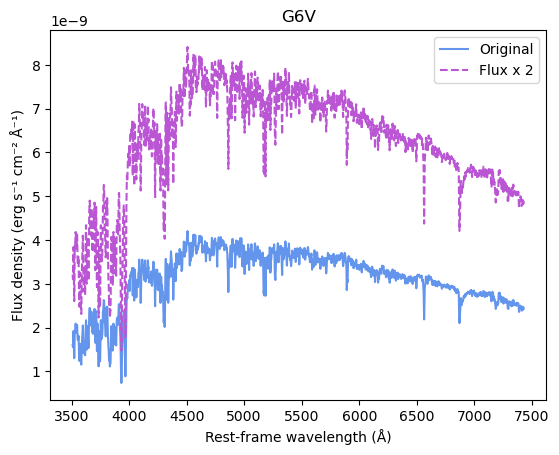

In [7]:
scale_factors = {"O5V": 0.5, "G6V": 2}

for star, factor in scale_factors.items():
    spectrum = spectra[star].assign(scaled_flux = spectra[star]["flux"] * factor)

    ax = spectrum.plot(x = "wavelength", y = "flux", color = "cornflowerblue", label = "Original", title = star)

    spectrum.plot(x = "wavelength", y = "scaled_flux", ax = ax, color = "mediumorchid", linestyle = "--", label = f"Flux x {factor}")

    ax.set_xlabel("Rest-frame wavelength (Å)")
    ax.set_ylabel("Flux density (erg s⁻¹ cm⁻² Å⁻¹)")

<Axes: title={'center': 'O5V / G6V'}, xlabel='Rest-frame wavelength (Å)', ylabel='Flux density ratio'>

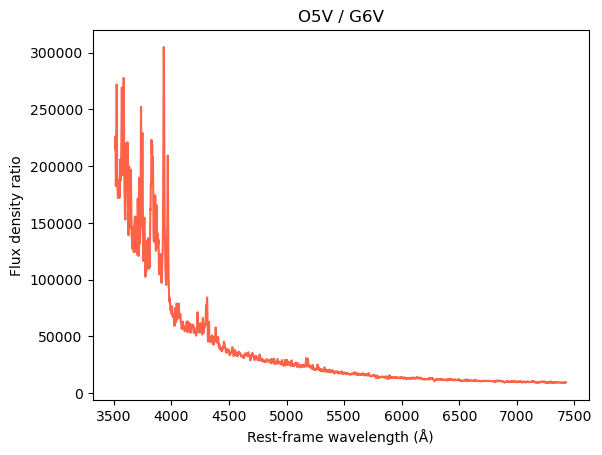

In [8]:
paired = spectra["O5V"].merge(spectra["G6V"], on="wavelength", suffixes=("_O5V", "_G6V"))

paired["ratio"] = paired["flux_O5V"].div(paired["flux_G6V"].where(paired["flux_G6V"].ne(0)))

paired.plot(x = "wavelength", y = "ratio", color = "tomato", title = "O5V / G6V",
    xlabel="Rest-frame wavelength (Å)",
    ylabel="Flux density ratio",
    legend=False)

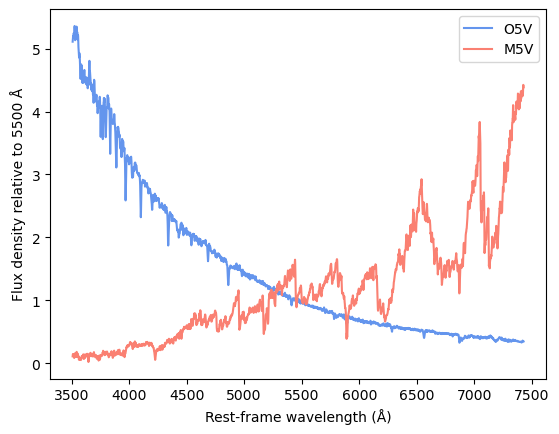

In [9]:
ax = None

for star, color in [("O5V", "cornflowerblue"), ("M5V", "salmon")]:
    spectrum = spectra[star]
    reference_row = (spectrum["wavelength"] - 5500).abs().idxmin()
    reference_flux = spectrum.loc[reference_row, "flux"]

    ax = spectrum.assign(relative_flux = spectrum["flux"] / reference_flux).plot(x = "wavelength", y = "relative_flux", ax = ax, color = color, label = star, xlabel = "Rest-frame wavelength (Å)", ylabel = "Flux density relative to 5500 Å")

## PART 2 A 

In [10]:
# Relative number of stars 
m_counts = {"M0V": 70, "M5V": 130}
k_counts = {"K4V": 25}
afg_counts = {"A6V": 4, "F0V": 8, "G6V": 13}
b_counts = {"B1p5V": 3, "B6V": 7}
o_counts = {"O5V": 0.3, "O8V": 0.7}

In [12]:
def make_box(counts):
    weighted_spectra = []

    for star, count in counts.items():
        spectrum = pd.read_csv(
            f"{star}.asc",
            sep=r"\s+",
            header=None,
            names=["wavelength", "flux_density"])

        # Lining up wavelengths 
        flux_density = spectrum.set_index("wavelength")["flux_density"]
        weighted_spectra.append(count * flux_density)

    # Keeping the wavelengths 
    return pd.concat(weighted_spectra, axis=1, join="inner").sum(axis=1)

box1 = make_box(m_counts)
box2 = make_box(k_counts)
box3 = make_box(afg_counts)
box4 = make_box(b_counts)
box5 = make_box(o_counts)

composite = pd.concat([box1, box2, box3, box4, box5], axis=1, join="inner").sum(axis=1)

print(composite.head())

wavelength
3510.0000    0.000281
3511.3999    0.000282
3512.8000    0.000283
3514.2000    0.000284
3515.6001    0.000283
dtype: float64


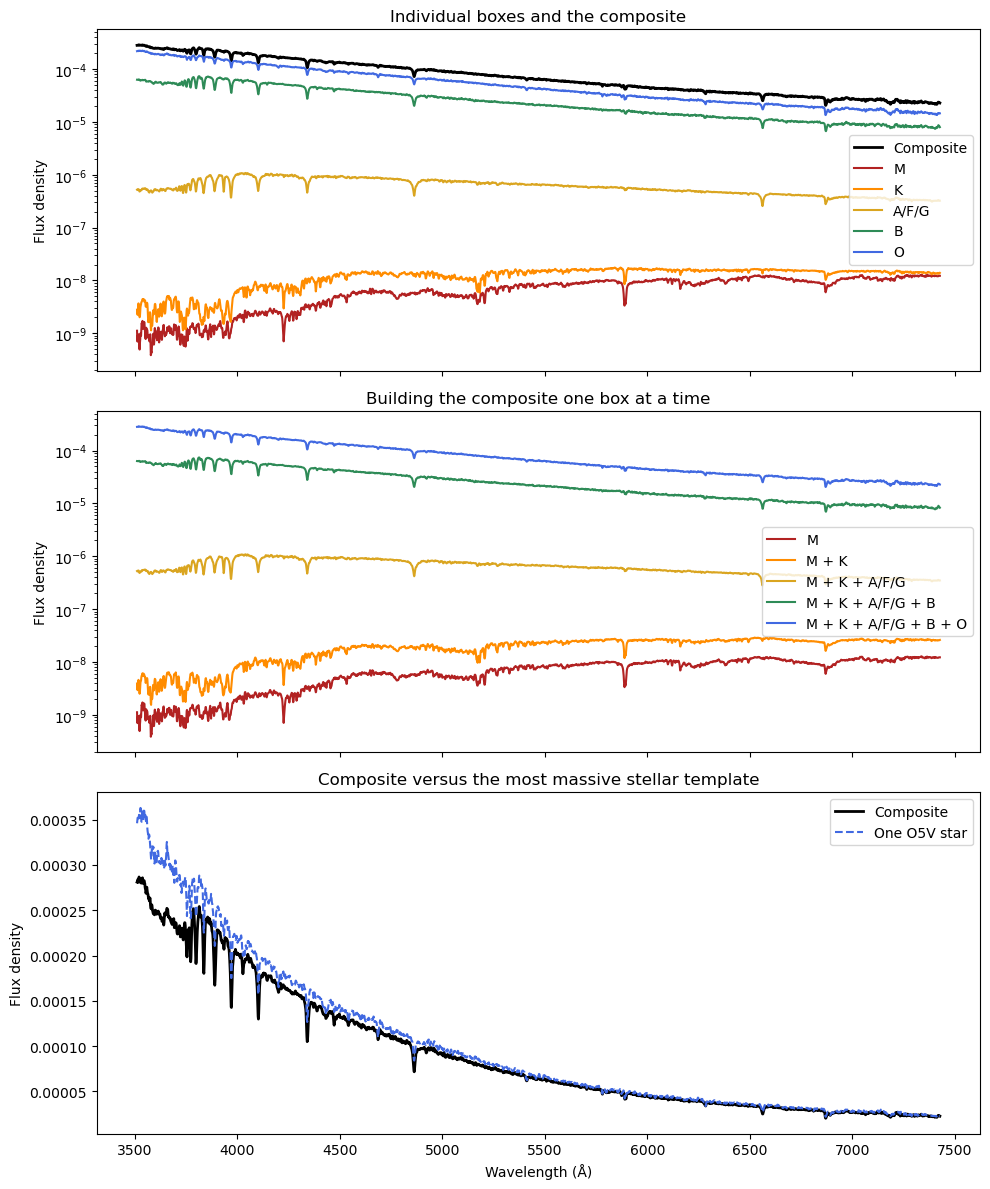

In [18]:
import matplotlib.pyplot as plt

boxes = [("M", box1, "firebrick"), ("K", box2, "darkorange"), ("A/F/G", box3, "goldenrod"), ("B", box4, "seagreen"), ("O", box5, "royalblue")]

fig, axes = plt.subplots(3, 1, figsize=(10, 12), sharex=True)

# 1 Compare each box contribution with the full composite
composite.plot(ax=axes[0], color="black", linewidth=2, label="Composite")
for name, spectrum, color in boxes:
    spectrum.plot(ax=axes[0], color=color, label=name)
axes[0].set_title("Individual boxes and the composite")

# Adding boxes from least to most massive - keeping a running sum 
running_sum = pd.Series(0.0, index=composite.index)
included = []
for name, spectrum, color in boxes:
    running_sum = running_sum + spectrum.reindex(composite.index)
    included.append(name)
    running_sum.plot(ax=axes[1], color=color, label=" + ".join(included))
axes[1].set_title("Building the composite one box at a time")

# Compare the composite with 1 O5V star.
o5_spectrum = make_box({"O5V": 1}).reindex(composite.index)
composite.plot(ax=axes[2], color="black", linewidth=2, label="Composite")
o5_spectrum.plot(ax=axes[2], color="royalblue", linestyle="--", label="One O5V star")
axes[2].set_title("Composite versus the most massive stellar template")

for ax in axes:
    ax.set_ylabel("Flux density")
    ax.legend()

axes[-1].set_xlabel("Wavelength (Å)")
axes[0].set_yscale("log")
axes[1].set_yscale("log")
fig.tight_layout()


1. Idividual boxes versus the composite

The O box contributes the most flux across the plotted range, followed by the B box. The M, K and A/F/G boxes are much fainter and are easier to see on a logaritmic scale

2. Adding the boxes from least to most massive

The first three running sums stay low. Adding B stars produces a clear increase, and adding the O box produces the largest increase, especially at short wavelengths. The last running sum is the full composite

3. Composite versus one O5V star
Both spectra decline toward longer wavelengths and share several absorption dips. The single O5V star is brighter at the blue end, while the curves are closer together toward the red end. This is consistent with the composite using a weigth of 0.3 for O5V and also including light from the other templates 

## Part 2 B

The composite spectrum represents the combined light of a model population of newly formed stars. We weighted each stellar spectrum by the relative abundance of its spectral type in our approximation to the initial mass function. Although M stars are the most numerous, the O stars contribute the most flux across the plotted wavelength range, followed by the B stars.

The composite resembles the spectrum of a single O5V star. Both show a general decline in flux density from blue to red and share several absorption dips. The single O5V star is brighter at the blue end, while the two curves are closer together toward the red end. The composite includes contributions from several stellar types, so its overall slope and the depths of its absorption features reflect their combined light.

## Part 3

# A) 

Galaxy 1: 1743 samples, 1235–9945 Å
Galaxy 2: 1741 samples, 1235–9935 Å


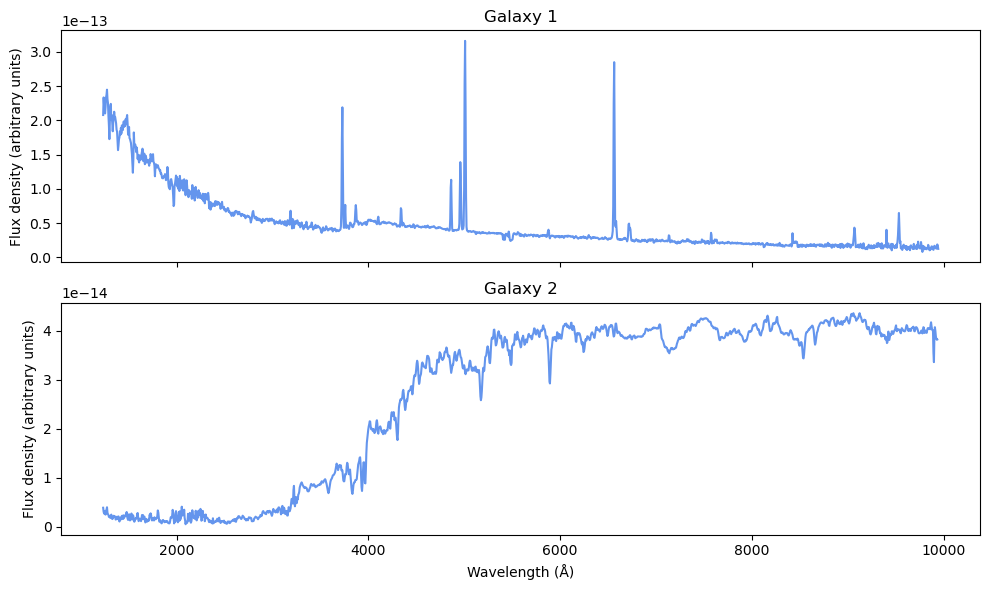

In [22]:
def read_galaxy(filename):
    flux, header = fits.getdata(filename, header=True)

    pixels = np.arange(1, flux.size + 1)
    wavelength = header["CRVAL1"] + (pixels - header["CRPIX1"]) * header["CDELT1"]
    return wavelength, flux

wave1, flux1 = read_galaxy("gal1.fits")
wave2, flux2 = read_galaxy("gal2.fits")

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

for ax, name, wavelength, flux in [
    (axes[0], "Galaxy 1", wave1, flux1),(axes[1], "Galaxy 2", wave2, flux2)]:
    ax.plot(wavelength, flux, color = "cornflowerblue")
    ax.set_title(name)
    ax.set_ylabel("Flux density (arbitrary units)")
    print(f"{name}: {len(wavelength)} samples, {wavelength[0]:g}–{wavelength[-1]:g} Å")

axes[-1].set_xlabel("Wavelength (Å)")
fig.tight_layout()

Both galaxy spectra have the same wavelength calibration. The FITS headers give CRPIX1 = 1, CRVAL1 = 1235 and CDELT1 = 5. This means that the first pixel corresponds to 1235 Å and the wavelength increases by 5 Å per pixel. The first three wavelengths are therefore 1235, 1240 and further. Galaxy 1 has 1743 samples and covers 1235-9945 Å, and Galaxy 2 has 1741 samples and covers 1235-9935Å. And the flux densities are in arbitraty units

# B)

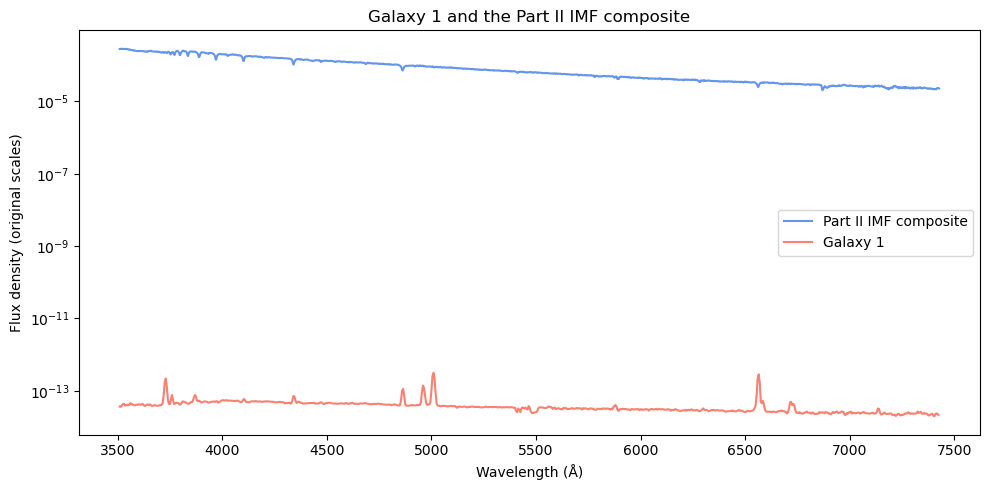

In [27]:
# Galaxy 1 samples within the composite wavelength range
lo, hi = composite.index.min(), composite.index.max()
overlap = (wave1 >= lo) & (wave1 <= hi)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(composite.index, composite, color="cornflowerblue", label="Part II IMF composite")
ax.plot(wave1[overlap], flux1[overlap], color="salmon", label="Galaxy 1")

ax.set_yscale("log")
ax.set_xlabel("Wavelength (Å)")
ax.set_ylabel("Flux density (original scales)")
ax.set_title("Galaxy 1 and the Part II IMF composite")
ax.legend()
fig.tight_layout()

Over the shared wavelength range, the IMF composite has flux density values around 10**-5 to 10**-4, while Galaxy 1 has values around 10**-14 and 10**-13. This puts the plotted amplitudes rougly nine order of magnitude apart. 
Galaxy 1 spectrum is on an arbitrary flux scale, so that the nummerical difference is not interprete as a physical brightness ratio